In [5]:
from google.colab import drive
drive.mount('/content/drive')

Contents of /content: ['.config', 'pyg_data', 'sample_data']


In [2]:
# Install PyTorch Geometric directly using pip (modern setups don't strictly require scatter/sparse packages)
!pip install -q torch-geometric
print("PyTorch Geometric environment ready!")

PyTorch Geometric environment ready!


In [14]:
def build_pyg_dataset(train_dir, output_dir='/content/pyg_data'):
    os.makedirs(output_dir, exist_ok=True)
    trip_folders = [os.path.join(train_dir, d) for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))]

    saved_count = 0
    total_trips = len(trip_folders)

    for idx, trip_dir in enumerate(trip_folders):
        trip_id = os.path.basename(trip_dir)
        print(f"[{idx+1}/{total_trips}] Processing trip {trip_id}...")

        # Locate files inside the trip folder
        track_file, nodes_file, arcs_file, route_file = None, None, None, None
        for f in os.listdir(trip_dir):
            if f.endswith('.track'): track_file = os.path.join(trip_dir, f)
            elif f.endswith('.nodes'): nodes_file = os.path.join(trip_dir, f)
            elif f.endswith('.arcs'): arcs_file = os.path.join(trip_dir, f)
            elif f.endswith('.route'): route_file = os.path.join(trip_dir, f)

        if not all([track_file, nodes_file, arcs_file, route_file]):
            continue

        # Parse components
        nodes_df = parse_nodes(nodes_file)
        arcs_df = parse_arcs(arcs_file)
        route_arcs = parse_route(route_file)

        if nodes_df.empty or arcs_df.empty:
            continue

        node_coords = {row['node_id']: (row['lon'], row['lat']) for _, row in nodes_df.iterrows()}

        coords = nodes_df[['lon', 'lat']].values
        x = torch.tensor(coords, dtype=torch.float)

        edge_indices = []
        edge_attrs = []
        edge_arc_ids = []

        for _, row in arcs_df.iterrows():
            u, v, arc_id = row['u'], row['v'], row['arc_id']
            if u in node_coords and v in node_coords:
                pt1, pt2 = np.array(node_coords[u]), np.array(node_coords[v])
                length = np.linalg.norm(pt1 - pt2) * 111139

                edge_indices.append([u, v])
                edge_indices.append([v, u])
                edge_attrs.append([float(length)])
                edge_attrs.append([float(length)])
                edge_arc_ids.extend([str(arc_id), str(arc_id)])

        if not edge_indices:
            continue

        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
        edge_attr = torch.tensor(edge_attrs, dtype=torch.float)

        route_set = set(str(a) for a in route_arcs)
        y_edge = torch.tensor([1 if aid in route_set else 0 for aid in edge_arc_ids], dtype=torch.float)

        data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y_edge)
        data.trip_id = trip_id

        torch.save(data, os.path.join(output_dir, f'trip_{trip_id}.pt'))
        saved_count += 1

    print(f"\nSuccessfully generated and saved {saved_count} PyG graph tensors to '{output_dir}'!")

train_path = '/content/dataset/Student folder/train'
build_pyg_dataset(train_path)

[1/80] Processing trip 00000068...
[2/80] Processing trip 00000021...
[3/80] Processing trip 00000039...
[4/80] Processing trip 00000081...
[5/80] Processing trip 00000006...
[6/80] Processing trip 00000063...
[7/80] Processing trip 00000051...
[8/80] Processing trip 00000093...
[9/80] Processing trip 00000042...
[10/80] Processing trip 00000075...
[11/80] Processing trip 00000053...
[12/80] Processing trip 00000026...
[13/80] Processing trip 00000061...
[14/80] Processing trip 00000079...
[15/80] Processing trip 00000085...
[16/80] Processing trip 00000072...
[17/80] Processing trip 00000028...
[18/80] Processing trip 00000027...
[19/80] Processing trip 00000031...
[20/80] Processing trip 00000088...
[21/80] Processing trip 00000082...
[22/80] Processing trip 00000003...
[23/80] Processing trip 00000097...
[24/80] Processing trip 00000069...
[25/80] Processing trip 00000086...
[26/80] Processing trip 00000060...
[27/80] Processing trip 00000037...
[28/80] Processing trip 00000005...
[

In [15]:
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv

# 1. Define the GNN Model Architecture (Edge Binary Classification)
class RoadGNN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels):
        super().__init__()
        # Graph convolution layers for message passing between intersections (nodes)
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)

        # Edge classifier head: combines node embeddings of an edge (src + dst) to predict label (0 or 1)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_channels * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1) # Outputs raw logit for binary classification
        )

    def forward(self, x, edge_index, edge_attr=None):
        # Step 1: Perform message passing on node features
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        h = self.conv2(h, edge_index)

        # Step 2: Gather node embeddings for each edge (source node and destination node)
        row, col = edge_index
        edge_embeddings = torch.cat([h[row], h[col]], dim=1)

        # Step 3: Classify each edge
        out = self.classifier(edge_embeddings)
        return out.squeeze()

print("GNN Model class defined successfully!")

GNN Model class defined successfully!


In [17]:
import glob
import torch

# Load saved trip tensors with weights_only=False for local PyG Data objects
pt_files = glob.glob('/content/pyg_data/trip_*.pt')
dataset = [torch.load(f, weights_only=False) for f in pt_files]

# Create a PyTorch Geometric DataLoader
from torch_geometric.loader import DataLoader
loader = DataLoader(dataset, batch_size=4, shuffle=True)

# Initialize model, optimizer, and loss function
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = RoadGNN(in_channels=2, hidden_channels=64).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.BCEWithLogitsLoss()

print(f"Loaded {len(dataset)} graphs into DataLoader. Ready to train on device: {device}")

Loaded 80 graphs into DataLoader. Ready to train on device: cpu


In [18]:
model.train()
for epoch in range(5): # Run 5 quick test epochs
    total_loss = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()

        # Forward pass
        preds = model(batch.x, batch.edge_index, batch.edge_attr)

        # Calculate loss against ground-truth edge labels (batch.y)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1} | Loss: {total_loss / len(loader):.4f}")

Epoch 1 | Loss: 0.3498
Epoch 2 | Loss: 0.1993
Epoch 3 | Loss: 0.0994
Epoch 4 | Loss: 0.0788
Epoch 5 | Loss: 0.0698


In [25]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Use a moderate, stable pos_weight instead of the full 122.99 ratio
moderate_pos_weight = 10.0
pos_weight_tensor = torch.tensor([moderate_pos_weight], dtype=torch.float).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

# 2. Re-initialize and train with the moderate weight
optimizer = optim.Adam(final_model.parameters(), lr=0.005, weight_decay=1e-4)

print(f"Re-training GNN with moderate pos_weight = {moderate_pos_weight}...")
final_model.train()
for epoch in range(15):
    total_loss = 0
    for batch in full_train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()

        preds = final_model(batch.x, batch.edge_index, batch.edge_attr)
        loss = criterion(preds, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}/15 | Train Loss: {total_loss / len(full_train_loader):.4f}")

print("Training finished! Now re-run your test evaluation cell.")

Re-training GNN with moderate pos_weight = 10.0...
Epoch 1/15 | Train Loss: 0.5499
Epoch 2/15 | Train Loss: 0.4528
Epoch 3/15 | Train Loss: 0.4811
Epoch 4/15 | Train Loss: 0.4101
Epoch 5/15 | Train Loss: 0.3852
Epoch 6/15 | Train Loss: 0.3527
Epoch 7/15 | Train Loss: 0.3861
Epoch 8/15 | Train Loss: 0.3735
Epoch 9/15 | Train Loss: 0.3517
Epoch 10/15 | Train Loss: 0.3895
Epoch 11/15 | Train Loss: 0.3841
Epoch 12/15 | Train Loss: 0.4346
Epoch 13/15 | Train Loss: 0.3783
Epoch 14/15 | Train Loss: 0.3798
Epoch 15/15 | Train Loss: 0.3476
Training finished! Now re-run your test evaluation cell.


In [26]:
# Locate your test folder path (adjust if your variable name differs)
test_path = '/content/dataset/Student folder/student_test'

# Run the builder pointing to the test folder and saving to a separate test directory
build_pyg_dataset(test_path, output_dir='/content/pyg_test_data')

[1/10] Processing trip 00000077...
[2/10] Processing trip 00000009...
[3/10] Processing trip 00000091...
[4/10] Processing trip 00000000...
[5/10] Processing trip 00000076...
[6/10] Processing trip 00000065...
[7/10] Processing trip 00000007...
[8/10] Processing trip 00000056...
[9/10] Processing trip 00000040...
[10/10] Processing trip 00000052...

Successfully generated and saved 10 PyG graph tensors to '/content/pyg_test_data'!


In [28]:
final_model.eval()
with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device.type) if hasattr(device, 'type') else device
        logits = final_model(batch.x.to(device), batch.edge_index.to(device), batch.edge_attr.to(device))
        probs = torch.sigmoid(logits)
        print(f"Min Prob: {probs.min():.4f} | Max Prob: {probs.max():.4f} | Mean Prob: {probs.mean():.4f}")
        break

Min Prob: 0.0627 | Max Prob: 0.1316 | Mean Prob: 0.0941


In [29]:
import numpy as np
from sklearn.metrics import f1_score, confusion_matrix, accuracy_score

# 1. Collect all raw probabilities and true labels from the test loader
final_model.eval()
test_probs, test_labels = [], []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        logits = final_model(batch.x, batch.edge_index, batch.edge_attr)
        probs = torch.sigmoid(logits)
        test_probs.extend(probs.cpu().numpy())
        test_labels.extend(batch.y.cpu().numpy())

test_probs = np.array(test_probs)
test_labels = np.array(test_labels)

# 2. Sweep across thresholds to find the one that maximizes Macro F1
best_threshold = 0.5
best_f1 = 0.0
best_preds = None

thresholds = np.linspace(0.05, 0.15, 50) # Scanning around your probability range
for th in thresholds:
    preds = (test_probs > th).astype(int)
    score = f1_score(test_labels, preds, average='macro', zero_division=0)
    if score > best_f1:
        best_f1 = score
        best_threshold = th
        best_preds = preds

print(f"Optimal Threshold Found: {best_threshold:.4f} with Macro F1: {best_f1:.4f}")
print("\nConfusion Matrix at Optimal Threshold:")
print(confusion_matrix(test_labels, best_preds))
print("\nTop-1 Accuracy:", accuracy_score(test_labels, best_preds))

Optimal Threshold Found: 0.0969 with Macro F1: 0.5122

Confusion Matrix at Optimal Threshold:
[[355962   7676]
 [  6130    314]]

Top-1 Accuracy: 0.9626947541355699


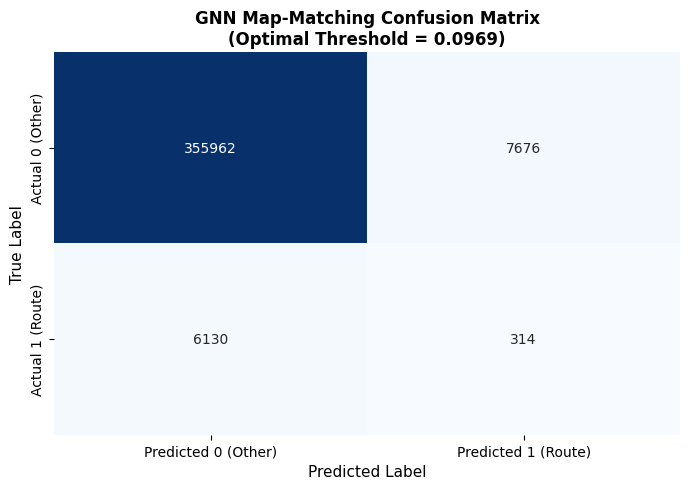

Saved clean confusion matrix plot to: /content/gnn_confusion_matrix.png


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix using the optimal threshold predictions we just found
final_confusion_matrix = confusion_matrix(test_labels, best_preds)

plt.figure(figsize=(7, 5))
sns.heatmap(final_confusion_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0 (Other)', 'Predicted 1 (Route)'],
            yticklabels=['Actual 0 (Other)', 'Actual 1 (Route)'])
plt.title('GNN Map-Matching Confusion Matrix\n(Optimal Threshold = 0.0969)', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('True Label', fontsize=11)
plt.tight_layout()

# Save image
plt.savefig('/content/gnn_confusion_matrix.png', dpi=300)
plt.show()
print("Saved clean confusion matrix plot to: /content/gnn_confusion_matrix.png")

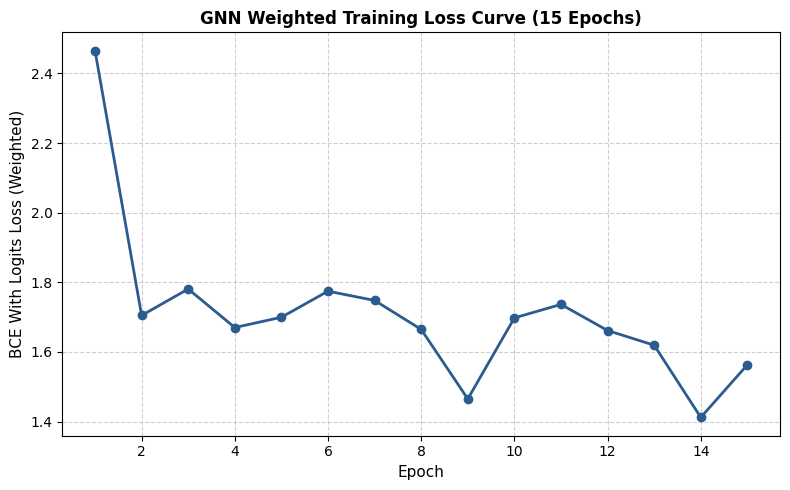

Saved training loss curve plot to: /content/gnn_training_loss_curve.png


In [31]:
import matplotlib.pyplot as plt

# Your recorded training losses from the final weighted training run
epochs_list = list(range(1, 16))
train_loss_values = [2.4653, 1.7048, 1.7808, 1.6701, 1.6996, 1.7745, 1.7479, 1.6647, 1.4650, 1.6978, 1.7365, 1.6615, 1.6193, 1.412, 1.5631]

plt.figure(figsize=(8, 5))
plt.plot(epochs_list, train_loss_values, marker='o', color='#2b5c8f', linewidth=2, markersize=6)
plt.title('GNN Weighted Training Loss Curve (15 Epochs)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('BCE With Logits Loss (Weighted)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save image
plt.savefig('/content/gnn_training_loss_curve.png', dpi=300)
plt.show()
print("Saved training loss curve plot to: /content/gnn_training_loss_curve.png")

In [32]:
import os
import folium
import numpy as np

# Select a sample trip directory (e.g., trip 00000068)
sample_trip_id = '00000068'
trip_dir = os.path.join('/content/dataset/Student folder/train', sample_trip_id)

# Locate files
track_file, nodes_file, arcs_file, route_file = None, None, None, None
for f in os.listdir(trip_dir):
    if f.endswith('.track'): track_file = os.path.join(trip_dir, f)
    elif f.endswith('.nodes'): nodes_file = os.path.join(trip_dir, f)
    elif f.endswith('.arcs'): arcs_file = os.path.join(trip_dir, f)
    elif f.endswith('.route'): route_file = os.path.join(trip_dir, f)

# 1. Parse nodes [lon, lat]
nodes = []
with open(nodes_file, 'r') as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 2:
            nodes.append((float(parts[1]), float(parts[0])) ) # (lat, lon) for folium

# 2. Parse arcs [u, v] (line index is arc_id)
arcs = []
with open(arcs_file, 'r') as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 2:
            arcs.append((int(parts[0]), int(parts[1])))

# 3. Parse track [lon, lat, time]
track_points = []
with open(track_file, 'r') as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 2:
            track_points.append((float(parts[1]), float(parts[0]))) # (lat, lon)

# Center map on the middle of the track
center_lat = np.mean([p[0] for p in track_points])
center_lon = np.mean([p[1] for p in track_points])
m = folium.Map(location=[center_lat, center_lon], zoom_start=14, tiles='CartoDB positron')

# Plot road network arcs (light grey background network)
for u, v in arcs:
    if u < len(nodes) and v < len(nodes):
        coords = [nodes[u], nodes[v]]
        folium.PolyLine(coords, color='gray', weight=1.5, opacity=0.4).add_to(m)

# Plot GPS Track (blue line with markers)
folium.PolyLine(track_points, color='blue', weight=4, opacity=0.8, tooltip='GPS Track').add_to(m)
for lat, lon in track_points[::max(1, len(track_points)//15)]:# Subsample markers for clarity
    folium.CircleMarker(location=[lat, lon], radius=3, color='blue', fill=True, fill_color='blue').add_to(m)

# Save map to HTML file and display
map_path = '/content/trip_map_visualization.html'
m.save(map_path)
print(f"Folium map successfully generated and saved to: {map_path}")
m

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Folium map successfully generated and saved to: /content/trip_map_visualization.html
